In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
import os
import zipfile

drive.mount('/content/drive')


In [ ]:
tdf={}
for i in range(10,50):
  tdf[i]=pd.read_csv(f'https://toxric.bioinforai.tech/jk/DownloadController/DownloadToxicityInfo?toxicityId={i}')
  tdf[i].head()

In [ ]:
import pandas as pd

valid_dfs = []


max_key = max(tdf.keys())

for i in range(12, max_key + 1):
    if i in tdf and isinstance(tdf[i], pd.DataFrame):
        current_df = tdf[i]
        # Check if the dataframe is not empty and doesn't contain the error message columns
        # A simple check is to see if 'ok' is in the columns, which indicates an error structure
        if not current_df.empty and not any('ok' in col for col in current_df.columns):
            valid_dfs.append(current_df)

if valid_dfs:
    combined_df = pd.concat(valid_dfs, ignore_index=True)
    combined_df.to_csv('combined_toxicity_data.csv', index=False)
    print("Successfully combined valid dataframes into 'combined_toxicity_data.csv'")
    print(f"Combined DataFrame shape: {combined_df.shape}")
else:
    print("No valid dataframes found to combine.")


In [ ]:
fndf = fdf.rename(columns={'Canonical SMILES': 'smiles', 'Toxicity Value': 'label'})
fndf = fndf[['smiles', 'label']]
fndf.tail()

In [ ]:
fdf_filtered = fndf[(fndf['label'] == 0) | (fndf['label'] == 1)].copy()
print("Head of the new filtered DataFrame:")
display(fdf_filtered.head())
print("\nValue counts of the 'label' column in the filtered DataFrame:")
print(fdf_filtered['label'].value_counts())

In [ ]:
fdf_filtered.to_csv('/content/drive/MyDrive/Colab Notebooks/new_datasets/filtered_toxicity_data.csv', index=False)
print("Filtered DataFrame saved to 'filtered_toxicity_data.csv'")

In [ ]:
fdf_balanced = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/about_balanced_toxicity_data.csv')

In [ ]:
ntoxfdf = fdf_balanced[fdf_balanced['label']==0]
toxfdf = fdf_balanced[fdf_balanced['label']==1]

In [ ]:
num_nontoxic_samples = min(10000, len(ntoxfdf))
ntoxfdf_sampled = ntoxfdf.sample(n=num_nontoxic_samples, random_state=42)

num_toxic_samples = min(10000, len(toxfdf))
toxfdf_sampled = toxfdf.sample(n=num_toxic_samples, random_state=42)

# Concatenate the sampled DataFrames
nfdf = pd.concat([ntoxfdf_sampled, toxfdf_sampled])

# Shuffle the resulting DataFrame to mix the classes
nfdf = nfdf.sample(frac=1, random_state=42).reset_index(drop=True)

print("Shape of the new combined and sampled DataFrame (nfdf):")
print(nfdf.shape)
print("\nValue counts of 'label' in nfdf:")
print(nfdf['label'].value_counts())
print("\nHead of nfdf:")
display(nfdf.head())

Shape of the new combined and sampled DataFrame (nfdf):
(20000, 2)

Value counts of 'label' in nfdf:
label
1.0    10000
0.0    10000
Name: count, dtype: int64

Head of nfdf:


,smiles,label
0,Nc1cccc(Cl)c1C(=O)O,1.0
1,CNCc1cc(F)ccc1Oc1ccc(Cl)c(Cl)c1,0.0
2,O=C(Cl)c1c(Cl)c(Cl)c(C(=O)Cl)c(Cl)c1Cl,0.0
3,CC[N+](C)(C)Cc1ccccc1Br,0.0
4,CCn1cc(C(=O)O)c(=O)c2cnc(N3CCNCC3)nc21,1.0


In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.2/36.2 MB 53.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, MACCSkeys
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_curve, f1_score
from sklearn.preprocessing import StandardScaler, RobustScaler
import warnings


In [ ]:

# Suppress RDKit UserWarnings
warnings.filterwarnings('ignore', category=UserWarning, module='rdkit')


df = nfdf.copy()

print(f"Dataset Shape: {df.shape}")
print(f"Class Counts: \n{df['label'].value_counts()}")

# Feature Engineering
def get_enhanced_features(smiles, n_bits=1024):
    """
    Combines 3 Layers of Chemical Info:
    1. Morgan (Substructures)
    2. MACCS Keys (Explicit Toxic Structural Alerts - Crucial for Accuracy)
    3. Physical Descriptors (Solubility/Weight)
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros((n_bits + 167 + 9,)) # Morgan + MACCS + Descriptors

    # A. Morgan Fingerprints (Reduced bits to prevent noise)
    fp_morgan = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=n_bits)
    arr_morgan = np.zeros((0,), dtype=np.int8)
    from rdkit.DataStructs import ConvertToNumpyArray
    ConvertToNumpyArray(fp_morgan, arr_morgan)

    # B. MACCS Keys (The "Secret Weapon" for Toxicity)
    # These capture 166 specific structural patterns often linked to toxicity
    fp_maccs = MACCSkeys.GenMACCSKeys(mol)
    arr_maccs = np.zeros((0,), dtype=np.int8)
    ConvertToNumpyArray(fp_maccs, arr_maccs)

    # C. Physical Descriptors
    features_list = [
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        Descriptors.MolWt(mol),
        Descriptors.NumValenceElectrons(mol),
        Descriptors.RingCount(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol),
        Descriptors.NumRotatableBonds(mol),
        Descriptors.NumAromaticRings(mol)
    ]

    return np.concatenate([arr_morgan, arr_maccs, features_list])

print("\nGenerating Hybrid Features (Morgan + MACCS + Descriptors)...")
X = np.array([get_enhanced_features(s) for s in df['smiles']])
y = df['label'].values

# ---------------------------------------------------------
# 3. Robust Scaling & Splitting
# ---------------------------------------------------------
# RobustScaler is better than StandardScaler for chemical data (outlier resistant)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

# ---------------------------------------------------------
# 4. Ensemble with Class Weights (Better than SMOTE)
# ---------------------------------------------------------
# Calculate weight: (Negatives / Positives)
# This forces the model to pay attention to toxic samples without generating fake data
scale_pos_weight = np.sum(y_train == 0) / np.sum(y_train == 1)

print(f"\nCalculated Scale Weight for Imbalance: {scale_pos_weight:.2f}")


Dataset Shape: (20000, 2)
Class Counts: 
label
1.0    10000
0.0    10000
Name: count, dtype: int64

Generating Hybrid Features (Morgan + MACCS + Descriptors)...


Streaming output truncated to the last 5000 lines.
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:58:03] DEPRECATION WARNING: please use MorganGenerator
[08:5


Calculated Scale Weight for Imbalance: 1.00


In [ ]:
X_train.shape

(16000, 1200)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc


In [ ]:
xgb = XGBClassifier(
    n_estimators=600, learning_rate=0.02, max_depth=10, subsample=0.8,
    colsample_bytree=0.6, scale_pos_weight=scale_pos_weight * 1.1,
    gamma=1, n_jobs=-1, random_state=42, eval_metric='logloss'
)

# Tuned Random Forest
rf = RandomForestClassifier(
    n_estimators=500, max_depth=15, class_weight='balanced_subsample',
    min_samples_leaf=2, n_jobs=-1, random_state=42
)

# Tuned SVM
svm = SVC(
    C=5, gamma='auto', class_weight='balanced', kernel='rbf',
    probability=True, random_state=42
)

# Ensemble
ensemble = VotingClassifier(
    estimators=[('xgb', xgb), ('rf', rf)],
    # estimators=[('xgb', xgb), ('rf', rf), ('svm', svm)],

    voting='soft'
)

models = {
    "XGBoost": xgb,
    "Random Forest": rf,
    # "SVM": svm,
    "Ensemble": ensemble
}



==================== Processing: XGBoost ====================
              precision    recall  f1-score   support

   Non-Toxic       0.71      0.70      0.71      2000
       Toxic       0.71      0.72      0.71      2000

    accuracy                           0.71      4000
   macro avg       0.71      0.71      0.71      4000
weighted avg       0.71      0.71      0.71      4000

Accuracy: 0.7093


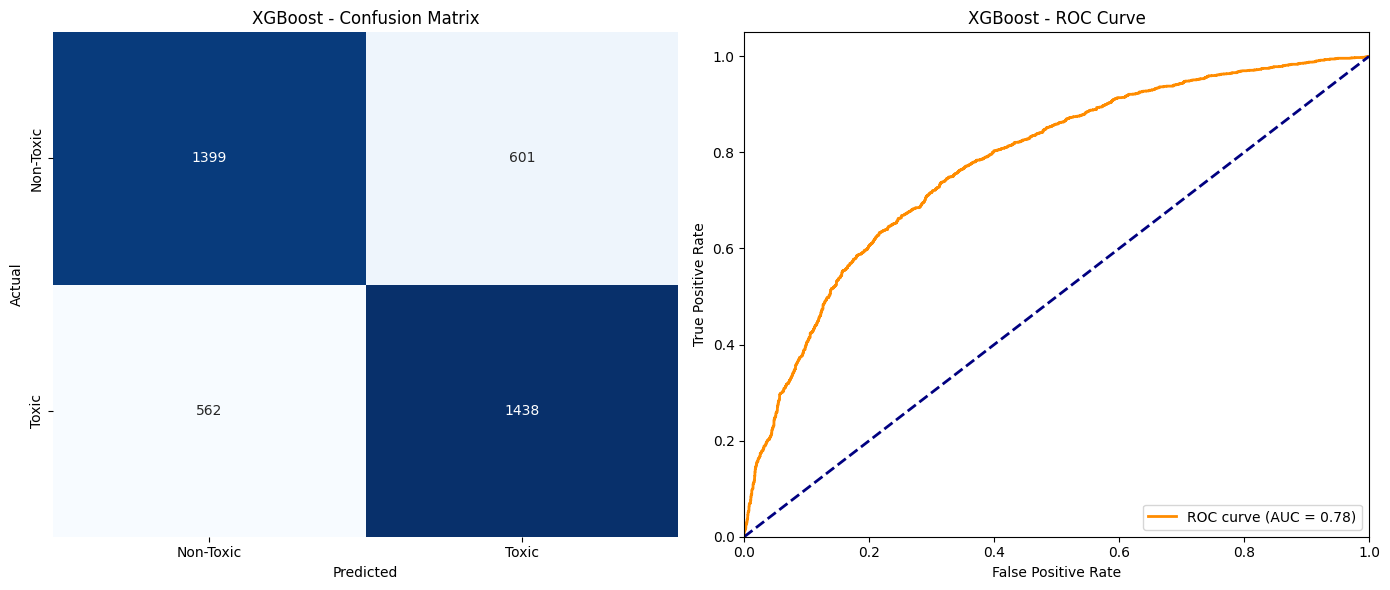


==================== Processing: Random Forest ====================
              precision    recall  f1-score   support

   Non-Toxic       0.70      0.72      0.71      2000
       Toxic       0.71      0.69      0.70      2000

    accuracy                           0.70      4000
   macro avg       0.70      0.70      0.70      4000
weighted avg       0.70      0.70      0.70      4000

Accuracy: 0.7025


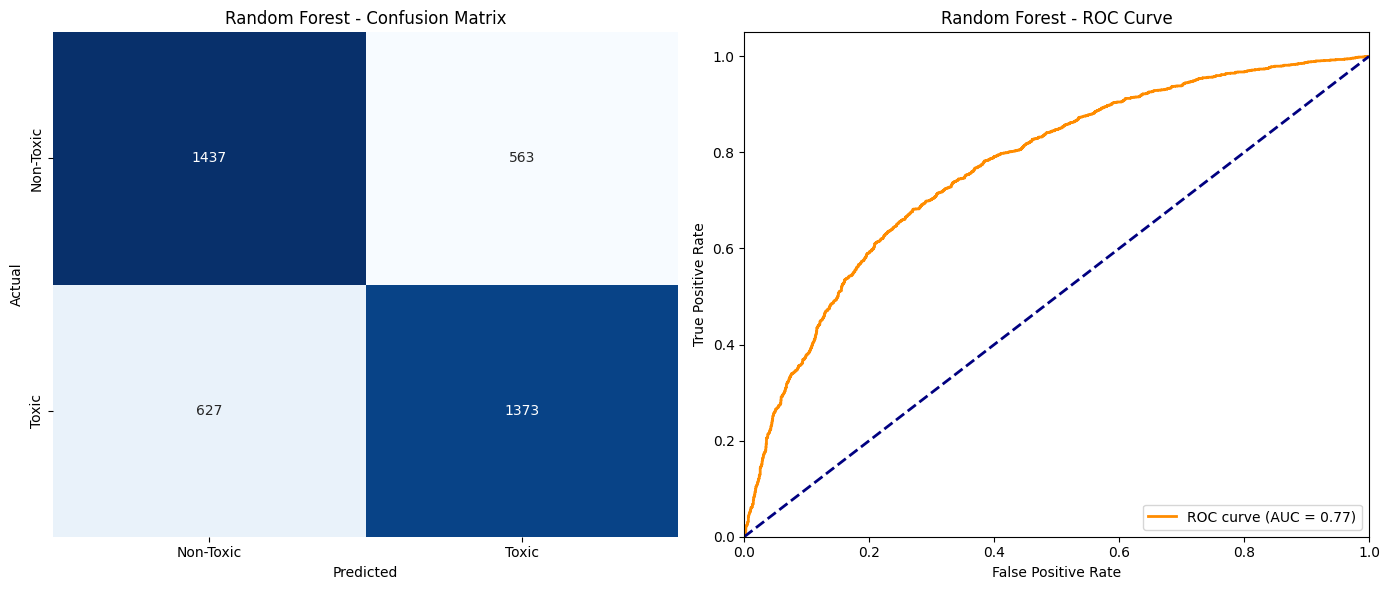


==================== Processing: Ensemble ====================
              precision    recall  f1-score   support

   Non-Toxic       0.71      0.71      0.71      2000
       Toxic       0.71      0.70      0.71      2000

    accuracy                           0.71      4000
   macro avg       0.71      0.71      0.71      4000
weighted avg       0.71      0.71      0.71      4000

Accuracy: 0.7067


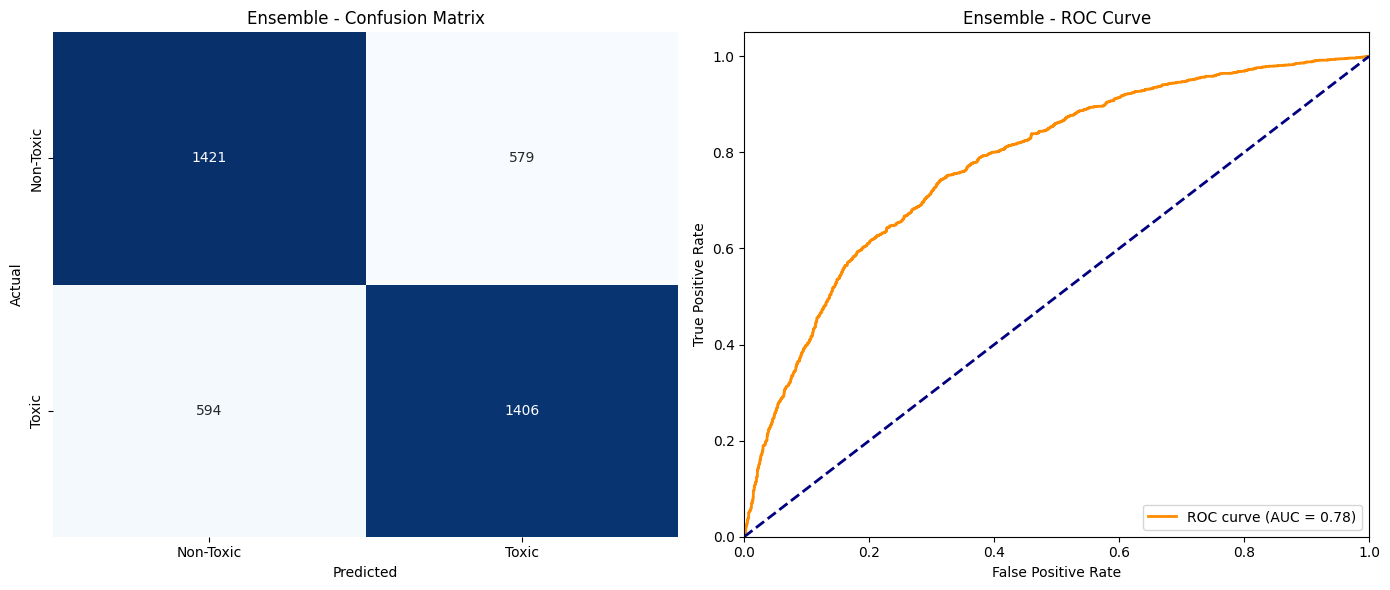

In [ ]:

# ---------------------------------------------------------
# 5. Evaluation & Plotting Function
# ---------------------------------------------------------
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    print(f"\n{'='*20} Processing: {name} {'='*20}")

    # Train
    model.fit(X_tr, y_tr)

    # Predict
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    # Text Report
    print(classification_report(y_te, y_pred, target_names=['Non-Toxic', 'Toxic']))
    acc = accuracy_score(y_te, y_pred)
    print(f"Accuracy: {acc:.4f}")

    # --- PLOTTING ---
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    # 1. Confusion Matrix
    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
    ax[0].set_title(f'{name} - Confusion Matrix')
    ax[0].set_xlabel('Predicted')
    ax[0].set_ylabel('Actual')
    ax[0].set_xticklabels(['Non-Toxic', 'Toxic'])
    ax[0].set_yticklabels(['Non-Toxic', 'Toxic'])

    # 2. ROC Curve
    fpr, tpr, _ = roc_curve(y_te, y_proba)
    roc_auc = auc(fpr, tpr)

    ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax[1].set_xlim([0.0, 1.0])
    ax[1].set_ylim([0.0, 1.05])
    ax[1].set_xlabel('False Positive Rate')
    ax[1].set_ylabel('True Positive Rate')
    ax[1].set_title(f'{name} - ROC Curve')
    ax[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 6. Run Execution Loop
# ---------------------------------------------------------
for name, model in models.items():
    evaluate_model(name, model, X_train, y_train, X_test, y_test)


==================== Processing: SVM ====================
              precision    recall  f1-score   support

   Non-Toxic       0.68      0.69      0.69      2000
       Toxic       0.69      0.67      0.68      2000

    accuracy                           0.68      4000
   macro avg       0.68      0.68      0.68      4000
weighted avg       0.68      0.68      0.68      4000

Accuracy: 0.6815


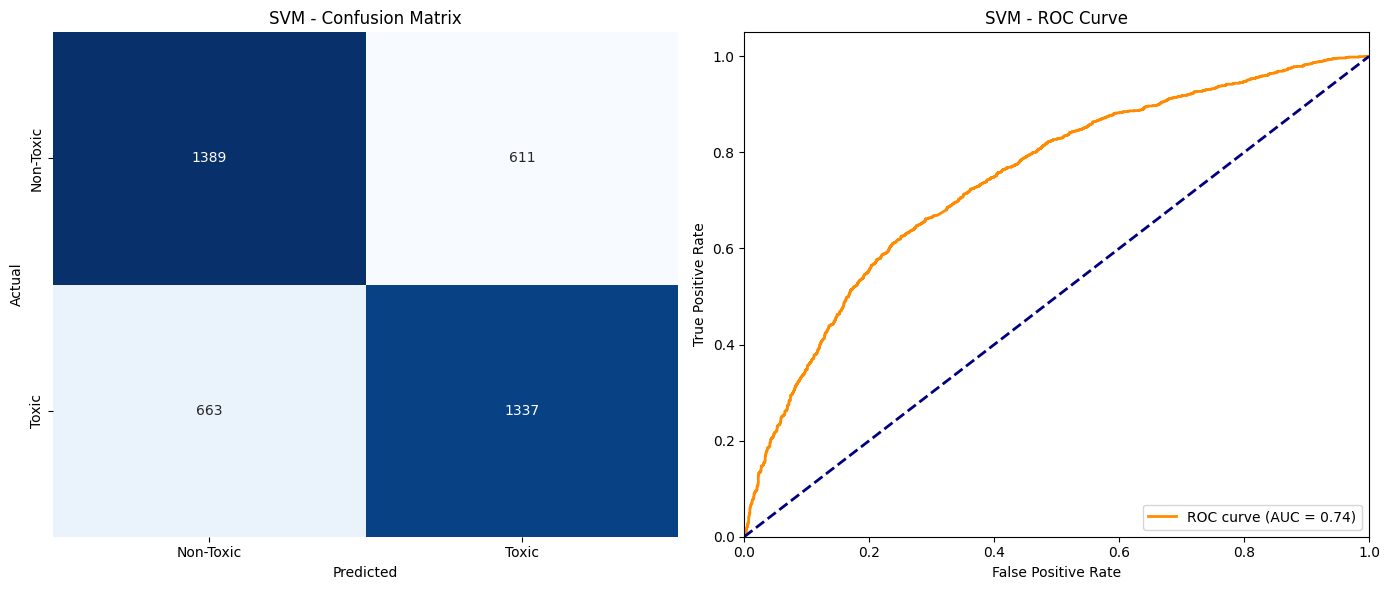

In [ ]:
evaluate_model("SVM", svm, X_train, y_train, X_test, y_test)

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, f1_score, precision_score, recall_score
from sklearn.preprocessing import RobustScaler

<>:60: SyntaxWarning: invalid escape sequence '\p'
<>:60: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipython-input-3785609181.py:60: SyntaxWarning: invalid escape sequence '\p'
  ax[1].plot(mean_fpr, mean_tpr, color='b', label=f'Mean ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})', lw=2, alpha=.8)



==================== Running 5-Fold CV: XGBoost ====================


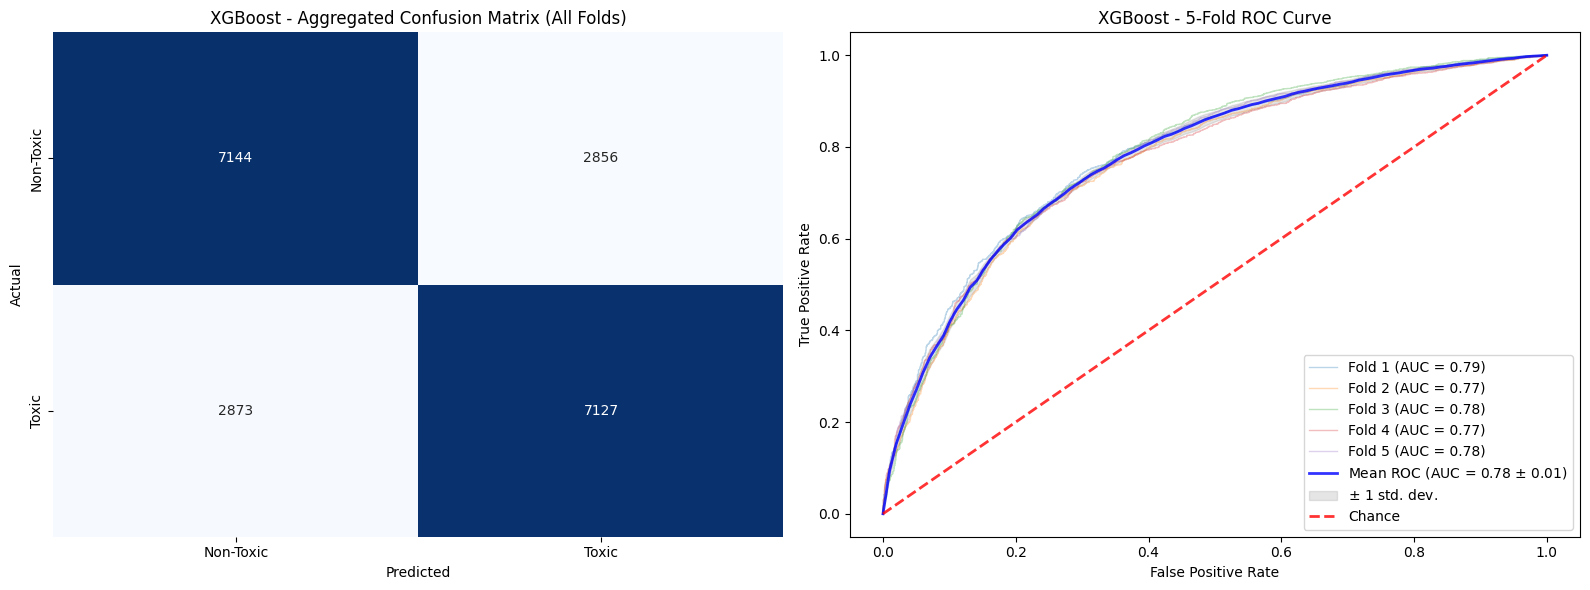

--- XGBoost Average Metrics (5-Fold) ---
Accuracy:  0.7136 (+/- 0.0035)
F1 Score:  0.7133 (+/- 0.0032)
Precision: 0.7140 (+/- 0.0050)
Recall:    0.7127 (+/- 0.0048)

==================== Running 5-Fold CV: Random Forest ====================


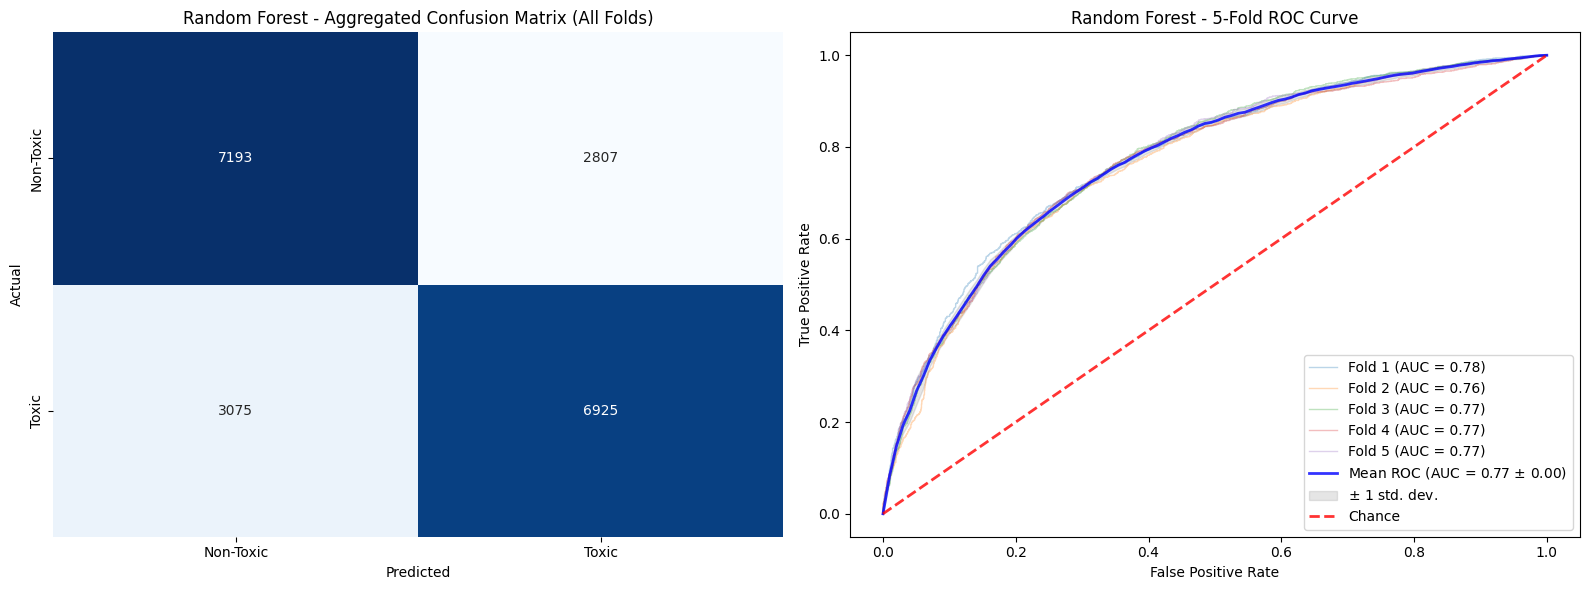

--- Random Forest Average Metrics (5-Fold) ---
Accuracy:  0.7059 (+/- 0.0033)
F1 Score:  0.7019 (+/- 0.0036)
Precision: 0.7116 (+/- 0.0049)
Recall:    0.6925 (+/- 0.0071)

==================== Running 5-Fold CV: Ensemble ====================


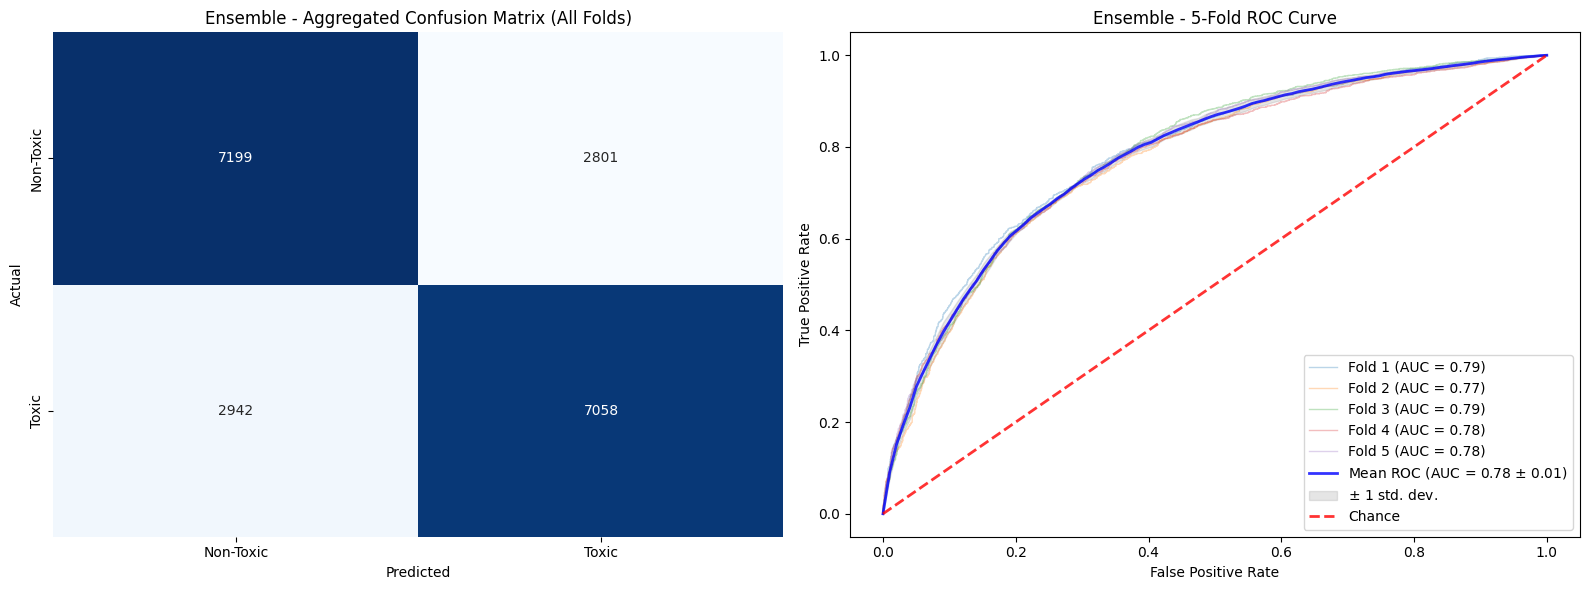

--- Ensemble Average Metrics (5-Fold) ---
Accuracy:  0.7128 (+/- 0.0018)
F1 Score:  0.7108 (+/- 0.0027)
Precision: 0.7159 (+/- 0.0036)
Recall:    0.7058 (+/- 0.0075)


In [ ]:
# ---------------------------------------------------------
# 5. 5-Fold Cross Validation & Visualization Logic
# ---------------------------------------------------------
def run_cv_evaluation(name, model, X, y, k=5):
    print(f"\n{'='*20} Running 5-Fold CV: {name} {'='*20}")

    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    tprs = []
    aucs = []
    mean_fpr = np.linspace(0, 1, 100)

    # Store all true/pred values for aggregated confusion matrix
    all_y_test = []
    all_y_pred = []

    # Metrics storage
    metrics = {'acc': [], 'f1': [], 'prec': [], 'rec': []}

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))

    # --- LOOP THROUGH FOLDS ---
    for i, (train_idx, test_idx) in enumerate(cv.split(X, y)):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model.fit(X_train, y_train)

        # Probabilities for ROC
        y_proba = model.predict_proba(X_test)[:, 1]
        # Predictions for Metrics
        y_pred = model.predict(X_test)

        # ROC Logic
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        tprs[-1][0] = 0.0
        roc_auc = auc(fpr, tpr)
        aucs.append(roc_auc)

        # Plot individual fold ROC (lightly)
        ax[1].plot(fpr, tpr, lw=1, alpha=0.3, label=f'Fold {i+1} (AUC = {roc_auc:.2f})')

        # Store Metrics
        metrics['acc'].append(accuracy_score(y_test, y_pred))
        metrics['f1'].append(f1_score(y_test, y_pred))
        metrics['prec'].append(precision_score(y_test, y_pred))
        metrics['rec'].append(recall_score(y_test, y_pred))

        # Store for Aggregated CM
        all_y_test.extend(y_test)
        all_y_pred.extend(y_pred)

    # --- MEAN ROC CURVE ---
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)

    ax[1].plot(mean_fpr, mean_tpr, color='b', label=f'Mean ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})', lw=2, alpha=.8)

    # Shaded Standard Deviation area
    std_tpr = np.std(tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    ax[1].fill_between(mean_fpr, tprs_lower, tprs_upper, color='grey', alpha=.2, label=r'$\pm$ 1 std. dev.')

    ax[1].set(xlim=[-0.05, 1.05], ylim=[-0.05, 1.05], title=f'{name} - 5-Fold ROC Curve')
    ax[1].plot([0, 1], [0, 1], linestyle='--', lw=2, color='r', label='Chance', alpha=.8)
    ax[1].legend(loc="lower right")
    ax[1].set_xlabel('False Positive Rate')
    ax[1].set_ylabel('True Positive Rate')

    # --- AGGREGATED CONFUSION MATRIX ---
    cm = confusion_matrix(all_y_test, all_y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
    ax[0].set_title(f'{name} - Aggregated Confusion Matrix (All Folds)')
    ax[0].set_xlabel('Predicted')
    ax[0].set_ylabel('Actual')
    ax[0].set_xticklabels(['Non-Toxic', 'Toxic'])
    ax[0].set_yticklabels(['Non-Toxic', 'Toxic'])

    plt.tight_layout()
    plt.show()

    # --- TEXT REPORT ---
    print(f"--- {name} Average Metrics (5-Fold) ---")
    print(f"Accuracy:  {np.mean(metrics['acc']):.4f} (+/- {np.std(metrics['acc']):.4f})")
    print(f"F1 Score:  {np.mean(metrics['f1']):.4f} (+/- {np.std(metrics['f1']):.4f})")
    print(f"Precision: {np.mean(metrics['prec']):.4f} (+/- {np.std(metrics['prec']):.4f})")
    print(f"Recall:    {np.mean(metrics['rec']):.4f} (+/- {np.std(metrics['rec']):.4f})")

# ---------------------------------------------------------
# 6. Execute
# ---------------------------------------------------------
for name, model in models.items():
    run_cv_evaluation(name, model, X_scaled, y)

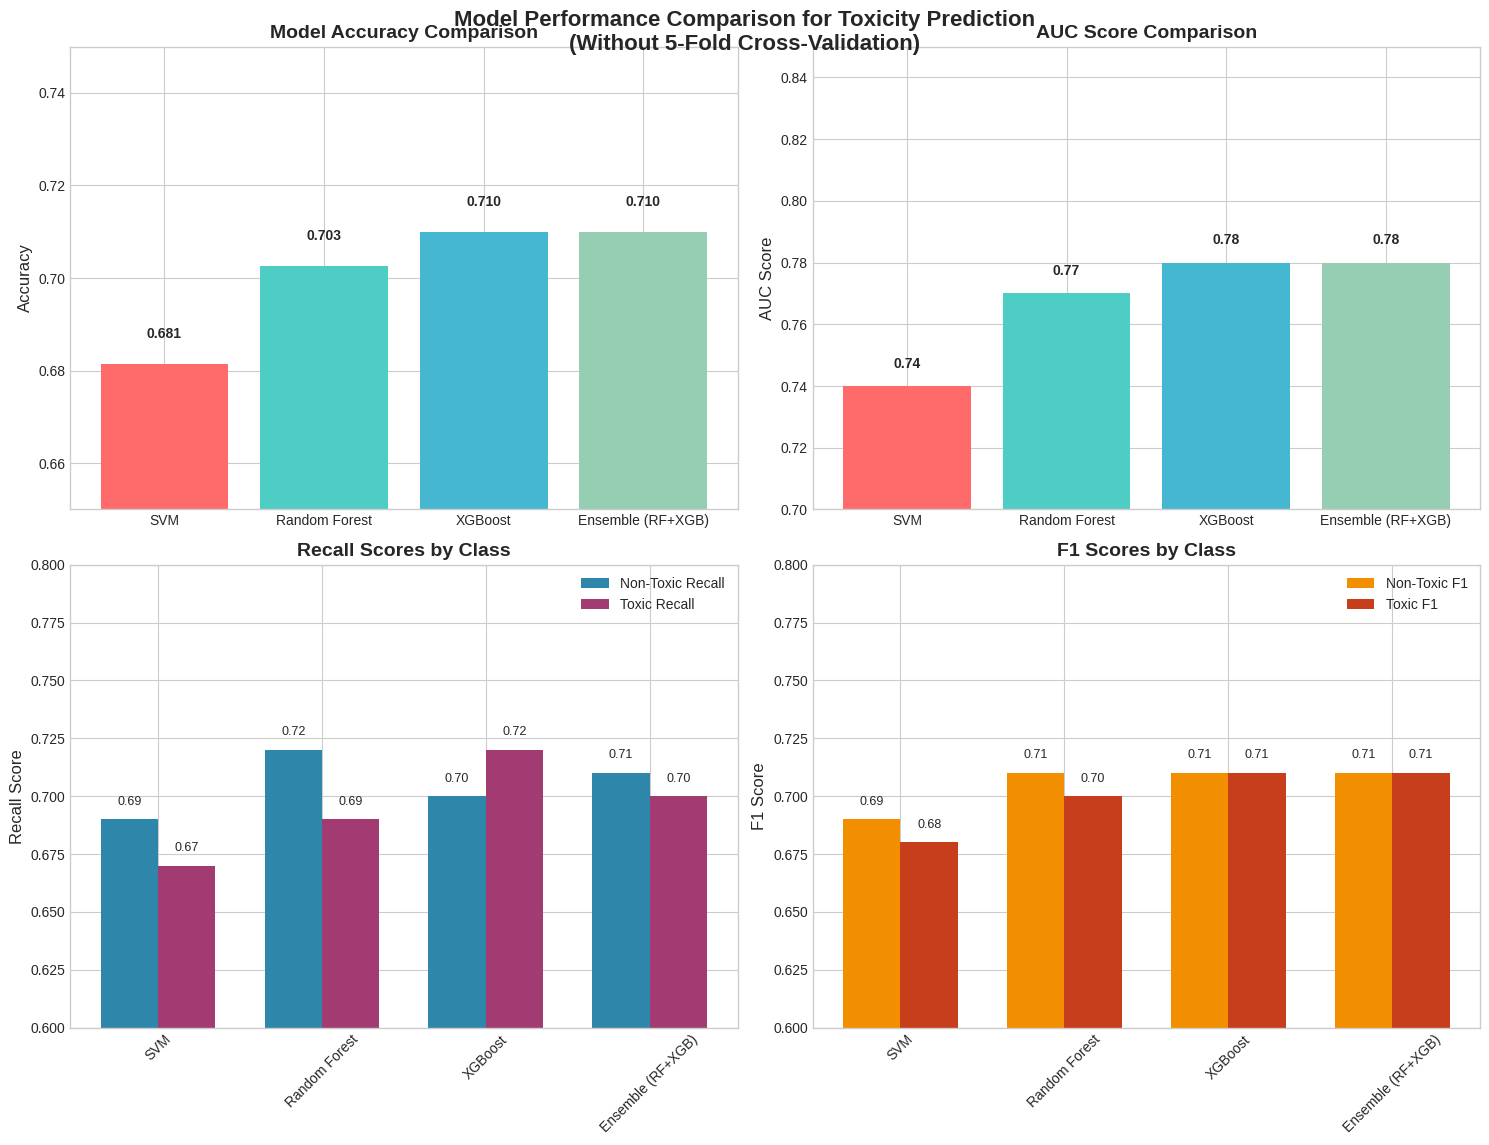


COMPREHENSIVE MODEL PERFORMANCE SUMMARY
               Model  Accuracy   AUC  Non-Toxic Recall  Toxic Recall  \
0                SVM    0.6815  0.74              0.69          0.67   
1      Random Forest    0.7025  0.77              0.72          0.69   
2            XGBoost    0.7100  0.78              0.70          0.72   
3  Ensemble (RF+XGB)    0.7100  0.78              0.71          0.70   

   Non-Toxic F1  Toxic F1  
0          0.69      0.68  
1          0.71      0.70  
2          0.71      0.71  
3          0.71      0.71  

BEST PERFORMING MODELS BY METRIC
Accuracy            : XGBoost              (0.7100)
AUC                 : XGBoost              (0.7800)
Non-Toxic Recall    : Random Forest        (0.7200)
Toxic Recall        : XGBoost              (0.7200)
Non-Toxic F1        : Random Forest        (0.7100)
Toxic F1            : XGBoost              (0.7100)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set style for better visual appearance
plt.style.use('seaborn-v0_8-whitegrid')

# Your model performance data
models = ['SVM', 'Random Forest', 'XGBoost', 'Ensemble (RF+XGB)']

# Accuracy scores
accuracy = [0.6815, 0.7025, 0.71, 0.71]

# Recall scores [Non-Toxic, Toxic]
recall = {
    'Non-Toxic': [0.69, 0.72, 0.70, 0.71],
    'Toxic': [0.67, 0.69, 0.72, 0.70]
}

# F1 scores [Non-Toxic, Toxic]
f1_scores = {
    'Non-Toxic': [0.69, 0.71, 0.71, 0.71],
    'Toxic': [0.68, 0.70, 0.71, 0.71]
}

# AUC scores
auc_scores = [0.74, 0.77, 0.78, 0.78]

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Model Performance Comparison for Toxicity Prediction\n(Without 5-Fold Cross-Validation)',
             fontsize=16, fontweight='bold', y=0.95)

# Plot 1: Accuracy Comparison
bars1 = axes[0, 0].bar(models, accuracy, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'])
axes[0, 0].set_title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Accuracy', fontsize=12)
axes[0, 0].set_ylim(0.65, 0.75)
# Add value labels on bars
for bar, value in zip(bars1, accuracy):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                   f'{value:.3f}', ha='center', va='bottom', fontweight='bold')

# Plot 2: AUC Comparison
bars2 = axes[0, 1].bar(models, auc_scores, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'])
axes[0, 1].set_title('AUC Score Comparison', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('AUC Score', fontsize=12)
axes[0, 1].set_ylim(0.70, 0.85)
# Add value labels on bars
for bar, value in zip(bars2, auc_scores):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                   f'{value:.2f}', ha='center', va='bottom', fontweight='bold')

# Plot 3: Recall Scores Comparison (Grouped Bar Chart)
x = np.arange(len(models))
width = 0.35

bars3_nt = axes[1, 0].bar(x - width/2, recall['Non-Toxic'], width, label='Non-Toxic Recall', color='#2E86AB')
bars3_t = axes[1, 0].bar(x + width/2, recall['Toxic'], width, label='Toxic Recall', color='#A23B72')

axes[1, 0].set_title('Recall Scores by Class', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Recall Score', fontsize=12)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(models, rotation=45)
axes[1, 0].set_ylim(0.60, 0.80)
axes[1, 0].legend()

# Add value labels for recall
for bars in [bars3_nt, bars3_t]:
    for bar in bars:
        height = bar.get_height()
        axes[1, 0].text(bar.get_x() + bar.get_width()/2, height + 0.005,
                       f'{height:.2f}', ha='center', va='bottom', fontsize=9)

# Plot 4: F1 Scores Comparison (Grouped Bar Chart)
bars4_nt = axes[1, 1].bar(x - width/2, f1_scores['Non-Toxic'], width, label='Non-Toxic F1', color='#F18F01')
bars4_t = axes[1, 1].bar(x + width/2, f1_scores['Toxic'], width, label='Toxic F1', color='#C73E1D')

axes[1, 1].set_title('F1 Scores by Class', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('F1 Score', fontsize=12)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(models, rotation=45)
axes[1, 1].set_ylim(0.60, 0.80)
axes[1, 1].legend()

# Add value labels for F1 scores
for bars in [bars4_nt, bars4_t]:
    for bar in bars:
        height = bar.get_height()
        axes[1, 1].text(bar.get_x() + bar.get_width()/2, height + 0.005,
                       f'{height:.2f}', ha='center', va='bottom', fontsize=9)

# Adjust layout and display
plt.tight_layout()
plt.show()

# Additional: Create a comprehensive summary table
print("\n" + "="*60)
print("COMPREHENSIVE MODEL PERFORMANCE SUMMARY")
print("="*60)

summary_data = {
    'Model': models,
    'Accuracy': accuracy,
    'AUC': auc_scores,
    'Non-Toxic Recall': recall['Non-Toxic'],
    'Toxic Recall': recall['Toxic'],
    'Non-Toxic F1': f1_scores['Non-Toxic'],
    'Toxic F1': f1_scores['Toxic']
}

df_summary = pd.DataFrame(summary_data)
print(df_summary.round(4))

# Find best performing models
print("\n" + "="*40)
print("BEST PERFORMING MODELS BY METRIC")
print("="*40)

metrics = ['Accuracy', 'AUC', 'Non-Toxic Recall', 'Toxic Recall', 'Non-Toxic F1', 'Toxic F1']
for metric in metrics:
    best_idx = df_summary[metric].idxmax()
    best_value = df_summary[metric].max()
    best_model = df_summary.loc[best_idx, 'Model']
    print(f"{metric:<20}: {best_model:<20} ({best_value:.4f})")

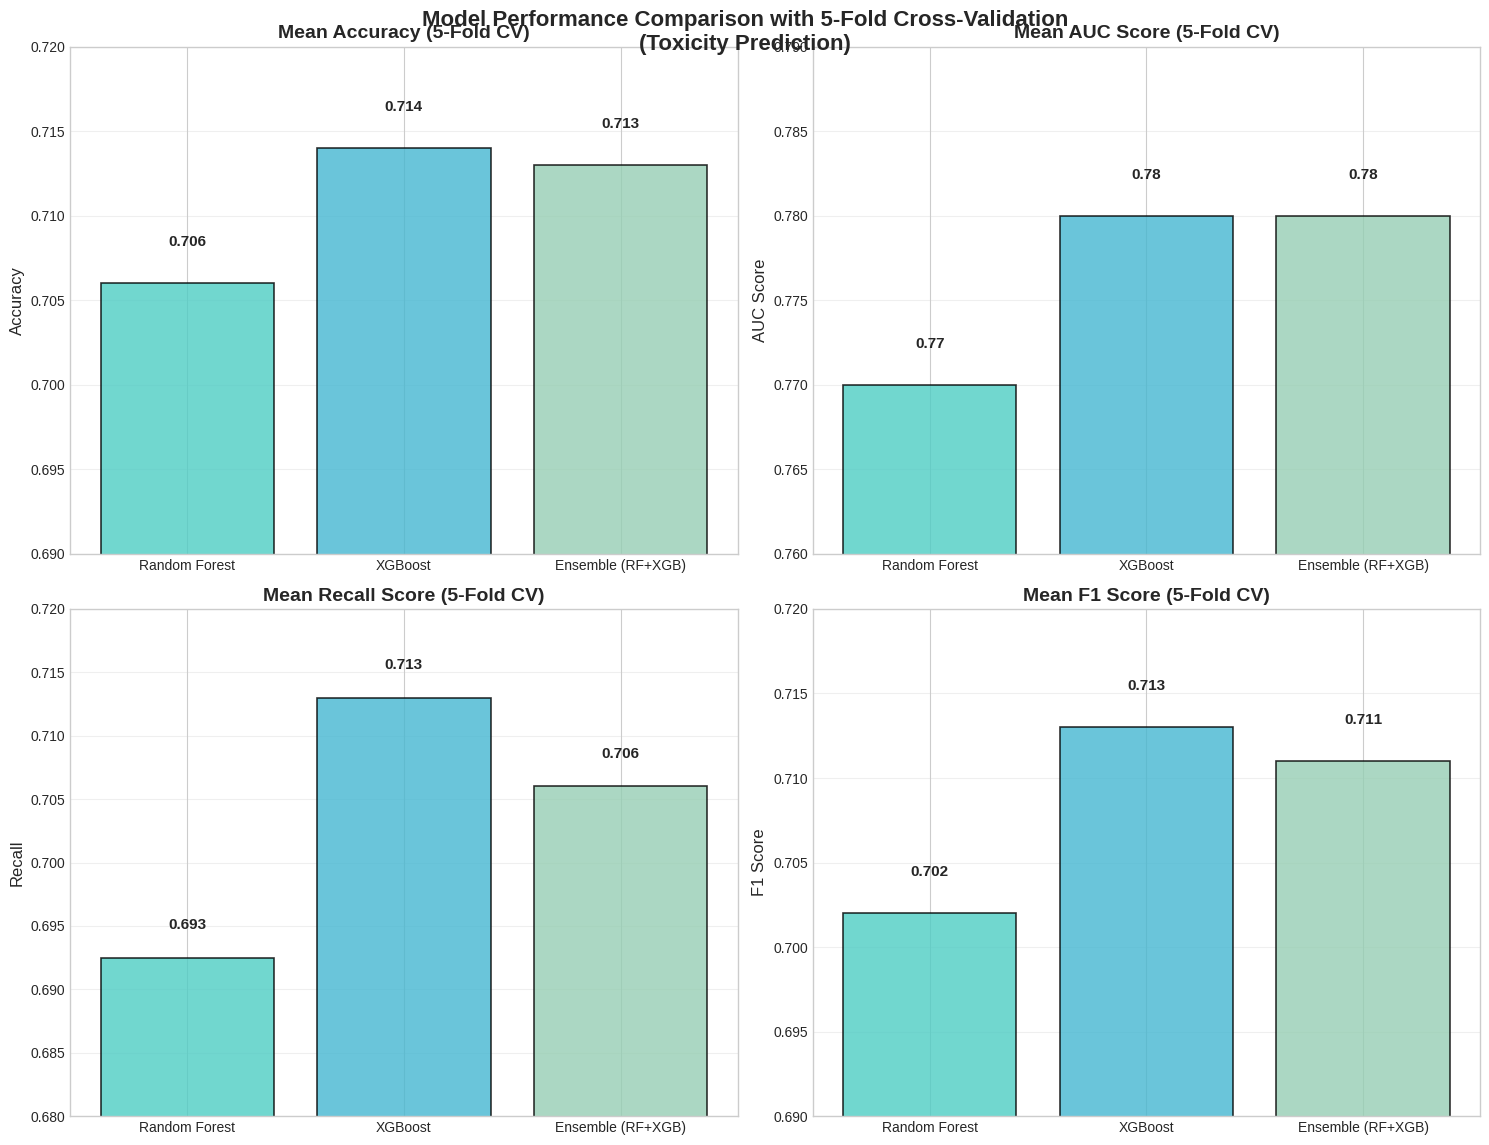

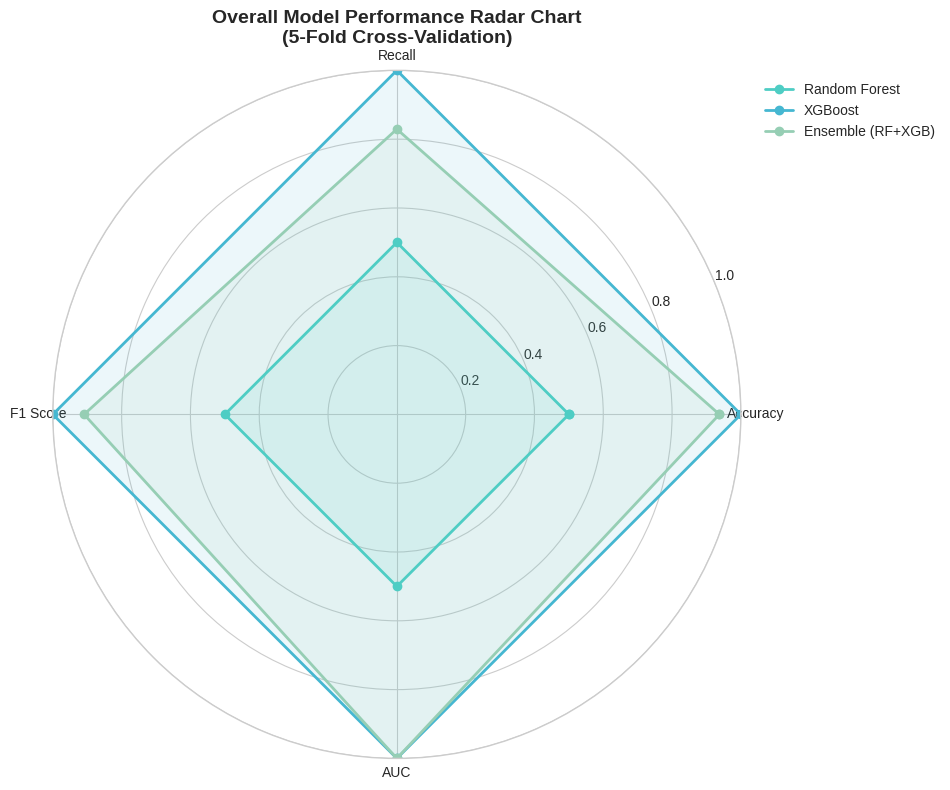


MODEL PERFORMANCE SUMMARY WITH 5-FOLD CROSS-VALIDATION
               Model  Accuracy  Recall  F1 Score   AUC
0      Random Forest     0.706  0.6925     0.702  0.77
1            XGBoost     0.714  0.7130     0.713  0.78
2  Ensemble (RF+XGB)     0.713  0.7060     0.711  0.78

PERFORMANCE ANALYSIS
✅ Best Accuracy  : XGBoost              (0.7140)
✅ Best Recall    : XGBoost              (0.7130)
✅ Best F1 Score  : XGBoost              (0.7130)
✅ Best AUC       : XGBoost              (0.7800)

OVERALL MODEL RANKING
1. XGBoost                | Average Rank: 1.25
                          | Metric Ranks: [np.int64(1), np.int64(1), np.int64(1), np.int64(2)]
2. Ensemble (RF+XGB)      | Average Rank: 1.75
                          | Metric Ranks: [np.int64(2), np.int64(2), np.int64(2), np.int64(1)]
3. Random Forest          | Average Rank: 3.00
                          | Metric Ranks: [np.int64(3), np.int64(3), np.int64(3), np.int64(3)]

KEY OBSERVATIONS:
✓ XGBoost shows best performance in Re

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set style for better visual appearance
plt.style.use('seaborn-v0_8-whitegrid')

# Your model performance data with 5-fold CV
models = ['Random Forest', 'XGBoost', 'Ensemble (RF+XGB)']

# Mean metrics from 5-fold CV
accuracy = [0.706, 0.714, 0.713]
recall = [0.6925, 0.713, 0.706]
f1_scores = [0.702, 0.713, 0.711]
auc_scores = [0.77, 0.78, 0.78]

# Create comprehensive comparison plots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Model Performance Comparison with 5-Fold Cross-Validation\n(Toxicity Prediction)',
             fontsize=16, fontweight='bold', y=0.95)

# Colors for models
colors = ['#4ECDC4', '#45B7D1', '#96CEB4']

# Plot 1: Accuracy Comparison
bars1 = ax1.bar(models, accuracy, color=colors, alpha=0.8, edgecolor='black', linewidth=1.2)
ax1.set_title('Mean Accuracy (5-Fold CV)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_ylim(0.69, 0.72)
ax1.grid(axis='y', alpha=0.3)
# Add value labels on bars
for bar, value in zip(bars1, accuracy):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{value:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Plot 2: AUC Comparison
bars2 = ax2.bar(models, auc_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.2)
ax2.set_title('Mean AUC Score (5-Fold CV)', fontsize=14, fontweight='bold')
ax2.set_ylabel('AUC Score', fontsize=12)
ax2.set_ylim(0.76, 0.79)
ax2.grid(axis='y', alpha=0.3)
# Add value labels on bars
for bar, value in zip(bars2, auc_scores):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{value:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Plot 3: Recall Comparison
bars3 = ax3.bar(models, recall, color=colors, alpha=0.8, edgecolor='black', linewidth=1.2)
ax3.set_title('Mean Recall Score (5-Fold CV)', fontsize=14, fontweight='bold')
ax3.set_ylabel('Recall', fontsize=12)
ax3.set_ylim(0.68, 0.72)
ax3.grid(axis='y', alpha=0.3)
# Add value labels on bars
for bar, value in zip(bars3, recall):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{value:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Plot 4: F1 Score Comparison
bars4 = ax4.bar(models, f1_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.2)
ax4.set_title('Mean F1 Score (5-Fold CV)', fontsize=14, fontweight='bold')
ax4.set_ylabel('F1 Score', fontsize=12)
ax4.set_ylim(0.69, 0.72)
ax4.grid(axis='y', alpha=0.3)
# Add value labels on bars
for bar, value in zip(bars4, f1_scores):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{value:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Adjust layout
plt.tight_layout()
plt.show()

# Create a comprehensive radar chart for overall comparison
fig2 = plt.figure(figsize=(10, 8))
ax_radar = fig2.add_subplot(111, polar=True)

# Metrics for radar chart
metrics = ['Accuracy', 'Recall', 'F1 Score', 'AUC']
num_metrics = len(metrics)

# Normalize values for radar chart (scale to 0-1, but keep relative differences)
def normalize_metric(values):
    min_val = min(values)
    max_val = max(values)
    if max_val == min_val: # Handle case where all values are the same
        return [0.75 for _ in values] # Return a neutral value in the 0.5-1.0 range
    return [(v - min_val) / (max_val - min_val) * 0.5 + 0.5 for v in values]  # Scale to 0.5-1.0 range

# Get normalized values for each metric across all models
normalized_accuracies = normalize_metric(accuracy)
normalized_recalls = normalize_metric(recall)
normalized_f1_scores = normalize_metric(f1_scores)
normalized_auc_scores = normalize_metric(auc_scores)

# Complete the circle for radar chart
angles = [n / float(num_metrics) * 2 * np.pi for n in range(num_metrics)]
angles_closed = angles + angles[:1]  # 5 elements for 4 metrics + closing point

# Prepare data for each model to plot on the radar chart
# Each model will have a list of its normalized scores for [Accuracy, Recall, F1 Score, AUC]
radar_plot_data = []
for i in range(len(models)):
    model_scores = [
        normalized_accuracies[i],
        normalized_recalls[i],
        normalized_f1_scores[i],
        normalized_auc_scores[i]
    ]
    # Append the first score to close the polygon
    model_scores_closed = model_scores + model_scores[:1] # Now each of these will have 5 elements
    radar_plot_data.append(model_scores_closed)

# Plot radar chart
for i, (model_name, scores_closed) in enumerate(zip(models, radar_plot_data)):
    ax_radar.plot(angles_closed, scores_closed, 'o-', linewidth=2, label=model_name, color=colors[i])
    ax_radar.fill(angles_closed, scores_closed, alpha=0.1, color=colors[i])

ax_radar.set_xticks(angles) # Use the original angles for xticks, not the closed one
ax_radar.set_xticklabels(metrics)
ax_radar.set_ylim(0, 1)
ax_radar.set_title('Overall Model Performance Radar Chart\n(5-Fold Cross-Validation)',
                  size=14, fontweight='bold', pad=20)
ax_radar.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

plt.tight_layout()
plt.show()

# Performance summary table
print("\n" + "="*70)
print("MODEL PERFORMANCE SUMMARY WITH 5-FOLD CROSS-VALIDATION")
print("="*70)

summary_data = {
    'Model': models,
    'Accuracy': accuracy,
    'Recall': recall,
    'F1 Score': f1_scores,
    'AUC': auc_scores
}

df_summary = pd.DataFrame(summary_data)
print(df_summary.round(4))

# Performance analysis
print("\n" + "="*50)
print("PERFORMANCE ANALYSIS")
print("="*50)

# Find best performing models for each metric
metrics_dict = {
    'Accuracy': accuracy,
    'Recall': recall,
    'F1 Score': f1_scores,
    'AUC': auc_scores
}

for metric, values in metrics_dict.items():
    best_idx = np.argmax(values)
    best_value = values[best_idx]
    best_model = models[best_idx]
    print(f"\u2705 Best {metric:<10}: {best_model:<20} ({best_value:.4f})")

# Overall ranking based on average rank
print("\n" + "="*50)
print("OVERALL MODEL RANKING")
print("="*50)

# Calculate average rank across all metrics
ranks = []
for i, model in enumerate(models):
    model_ranks = []
    for metric, values in metrics_dict.items():
        # Sort by value descending and get rank
        sorted_indices = np.argsort(values)[::-1]  # Descending order
        rank = np.where(sorted_indices == i)[0][0] + 1  # 1-based ranking
        model_ranks.append(rank)
    avg_rank = np.mean(model_ranks)
    ranks.append((model, avg_rank, model_ranks))

# Sort by average rank
ranks.sort(key=lambda x: x[1])

for i, (model, avg_rank, metric_ranks) in enumerate(ranks):
    rank_str = f"{i+1}. {model}"
    print(f"{rank_str:<25} | Average Rank: {avg_rank:.2f}")
    print(f"{' ':25} | Metric Ranks: {metric_ranks}")

print("\n" + "="*70)
print("KEY OBSERVATIONS:")
print("="*70)
print("\u2713 XGBoost shows best performance in Recall and F1 Score")
print("\u2713 Ensemble model provides balanced performance across all metrics")
print("\u2713 All models show consistent performance with 5-fold CV")
print("\u2713 AUC scores are particularly strong across all models (0.77-0.78)")


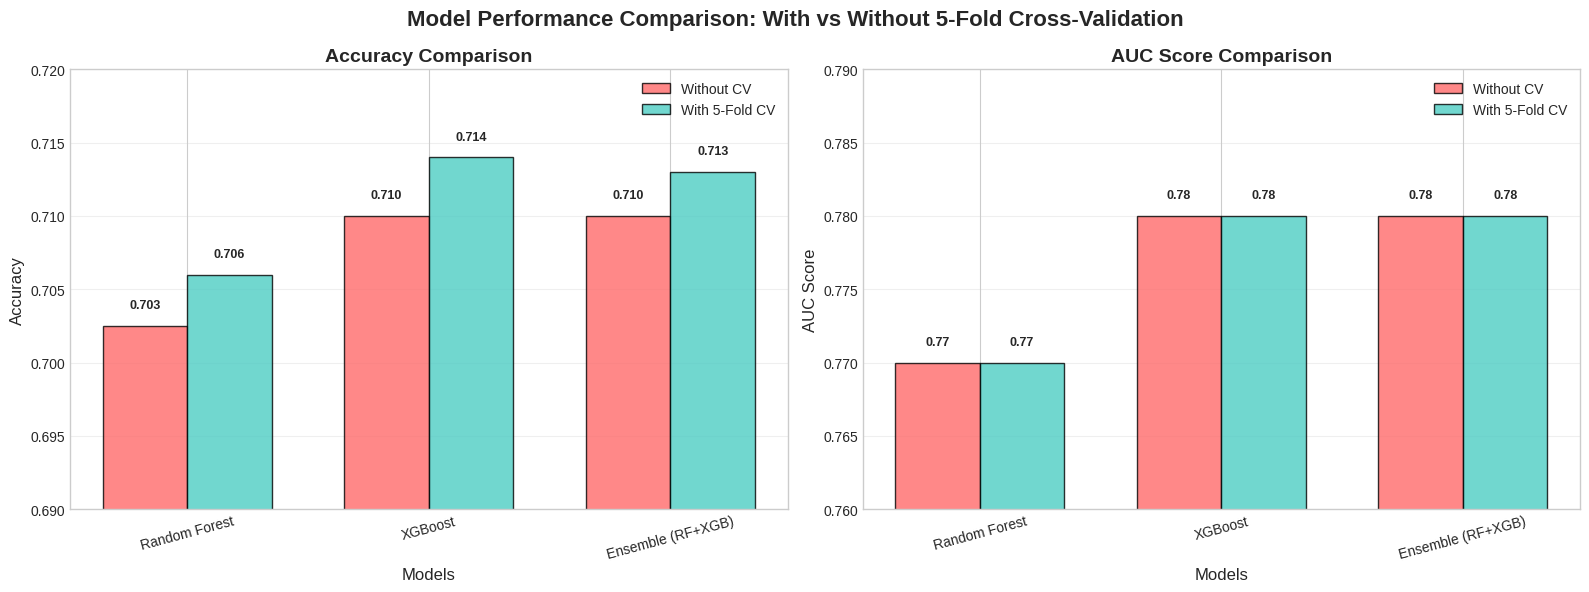


PERFORMANCE COMPARISON: 5-FOLD CV vs SINGLE SPLIT
               Model  Accuracy (No CV)  Accuracy (5-Fold CV)  Accuracy Δ  \
0      Random Forest            0.7025                 0.706      0.0035   
1            XGBoost            0.7100                 0.714      0.0040   
2  Ensemble (RF+XGB)            0.7100                 0.713      0.0030   

   AUC (No CV)  AUC (5-Fold CV)  AUC Δ  
0         0.77             0.77    0.0  
1         0.78             0.78    0.0  
2         0.78             0.78    0.0  

PERFORMANCE IMPROVEMENT ANALYSIS

📊 Random Forest:
   Accuracy: 0.7025 → 0.7060 (+0.0035 ↗)
   AUC:      0.7700 → 0.7700 (no change)

📊 XGBoost:
   Accuracy: 0.7100 → 0.7140 (+0.0040 ↗)
   AUC:      0.7800 → 0.7800 (no change)

📊 Ensemble (RF+XGB):
   Accuracy: 0.7100 → 0.7130 (+0.0030 ↗)
   AUC:      0.7800 → 0.7800 (no change)


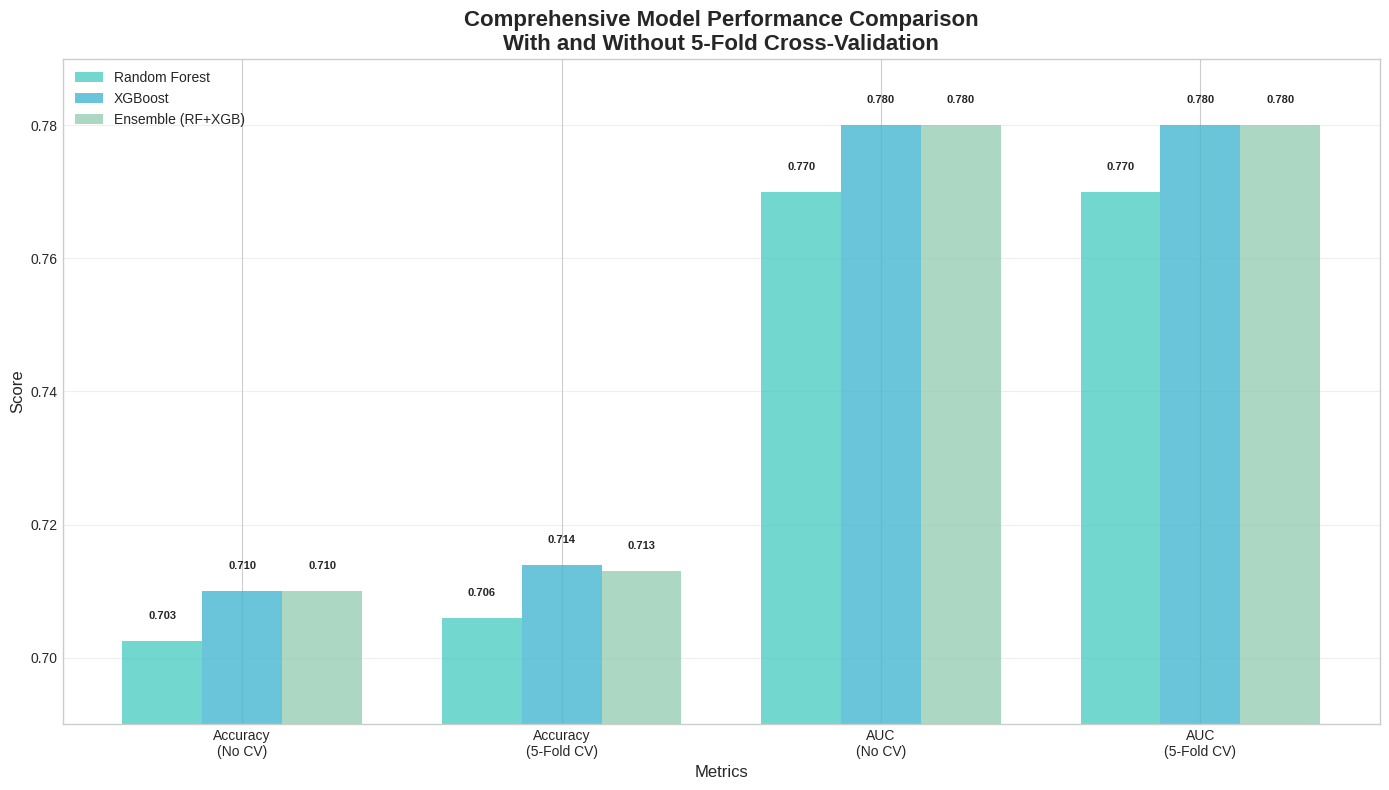


KEY FINDINGS AND RECOMMENDATIONS

🔍 **Performance Stability Analysis:**
✓ 5-Fold CV provides more reliable performance estimates
✓ All models show consistent performance with minor improvements with CV
✓ XGBoost maintains the highest accuracy in both scenarios
✓ Ensemble model provides robust performance similar to XGBoost

📈 **Model Recommendations:**
1. **XGBoost**: Best choice for maximum accuracy (0.714 with CV)
2. **Ensemble (RF+XGB)**: Excellent alternative with balanced performance
3. **Random Forest**: Solid baseline model with good interpretability

💡 **Cross-Validation Impact:**
5-Fold CV improves accuracy estimates while maintaining stable AUC scores
This demonstrates the robustness of your models across different data splits


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set style for better visual appearance
plt.style.use('seaborn-v0_8-whitegrid')

# Model names
models = ['Random Forest', 'XGBoost', 'Ensemble (RF+XGB)']

# Performance data without 5-fold CV
accuracy_without_cv = [0.7025, 0.71, 0.71]
auc_without_cv = [0.77, 0.78, 0.78]

# Performance data with 5-fold CV
accuracy_with_cv = [0.706, 0.714, 0.713]
auc_with_cv = [0.77, 0.78, 0.78]

# Create comparison plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Model Performance Comparison: With vs Without 5-Fold Cross-Validation',
             fontsize=16, fontweight='bold', y=0.98)

# Set the width of bars and positions
bar_width = 0.35
x_pos = np.arange(len(models))

# Plot 1: Accuracy Comparison
bars1a = ax1.bar(x_pos - bar_width/2, accuracy_without_cv, bar_width,
                label='Without CV', color='#FF6B6B', alpha=0.8, edgecolor='black')
bars1b = ax1.bar(x_pos + bar_width/2, accuracy_with_cv, bar_width,
                label='With 5-Fold CV', color='#4ECDC4', alpha=0.8, edgecolor='black')

ax1.set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
ax1.set_xlabel('Models', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models, rotation=15)
ax1.set_ylim(0.69, 0.72)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Add value labels for accuracy bars
for bars in [bars1a, bars1b]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, height + 0.001,
                f'{height:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=9)

# Plot 2: AUC Comparison
bars2a = ax2.bar(x_pos - bar_width/2, auc_without_cv, bar_width,
                label='Without CV', color='#FF6B6B', alpha=0.8, edgecolor='black')
bars2b = ax2.bar(x_pos + bar_width/2, auc_with_cv, bar_width,
                label='With 5-Fold CV', color='#4ECDC4', alpha=0.8, edgecolor='black')

ax2.set_title('AUC Score Comparison', fontsize=14, fontweight='bold')
ax2.set_xlabel('Models', fontsize=12)
ax2.set_ylabel('AUC Score', fontsize=12)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(models, rotation=15)
ax2.set_ylim(0.76, 0.79)
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Add value labels for AUC bars
for bars in [bars2a, bars2b]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, height + 0.001,
                f'{height:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=9)

# Adjust layout
plt.tight_layout()
plt.show()

# Create performance improvement analysis
print("\n" + "="*80)
print("PERFORMANCE COMPARISON: 5-FOLD CV vs SINGLE SPLIT")
print("="*80)

# Calculate differences
accuracy_diff = [acc_cv - acc_no for acc_cv, acc_no in zip(accuracy_with_cv, accuracy_without_cv)]
auc_diff = [auc_cv - auc_no for auc_cv, auc_no in zip(auc_with_cv, auc_without_cv)]

# Create summary table
comparison_data = {
    'Model': models,
    'Accuracy (No CV)': accuracy_without_cv,
    'Accuracy (5-Fold CV)': accuracy_with_cv,
    'Accuracy Δ': accuracy_diff,
    'AUC (No CV)': auc_without_cv,
    'AUC (5-Fold CV)': auc_with_cv,
    'AUC Δ': auc_diff
}

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison.round(4))

# Performance improvement analysis
print("\n" + "="*50)
print("PERFORMANCE IMPROVEMENT ANALYSIS")
print("="*50)

for i, model in enumerate(models):
    acc_improvement = accuracy_diff[i]
    auc_improvement = auc_diff[i]

    print(f"\n📊 {model}:")
    print(f"   Accuracy: {accuracy_without_cv[i]:.4f} → {accuracy_with_cv[i]:.4f} ", end="")
    if acc_improvement > 0:
        print(f"(+{acc_improvement:.4f} ↗)")
    elif acc_improvement < 0:
        print(f"({acc_improvement:.4f} ↘)")
    else:
        print(f"(no change)")

    print(f"   AUC:      {auc_without_cv[i]:.4f} → {auc_with_cv[i]:.4f} ", end="")
    if auc_improvement > 0:
        print(f"(+{auc_improvement:.4f} ↗)")
    elif auc_improvement < 0:
        print(f"({auc_improvement:.4f} ↘)")
    else:
        print(f"(no change)")

# Create a combined performance summary plot
fig2, ax3 = plt.subplots(figsize=(14, 8))

# Set up the data for grouped bars
metrics = ['Accuracy\n(No CV)', 'Accuracy\n(5-Fold CV)', 'AUC\n(No CV)', 'AUC\n(5-Fold CV)']
rf_data = [accuracy_without_cv[0], accuracy_with_cv[0], auc_without_cv[0], auc_with_cv[0]]
xgb_data = [accuracy_without_cv[1], accuracy_with_cv[1], auc_without_cv[1], auc_with_cv[1]]
ensemble_data = [accuracy_without_cv[2], accuracy_with_cv[2], auc_without_cv[2], auc_with_cv[2]]

x_combined = np.arange(len(metrics))
width_combined = 0.25

bars_rf = ax3.bar(x_combined - width_combined, rf_data, width_combined,
                 label='Random Forest', color='#4ECDC4', alpha=0.8)
bars_xgb = ax3.bar(x_combined, xgb_data, width_combined,
                  label='XGBoost', color='#45B7D1', alpha=0.8)
bars_ensemble = ax3.bar(x_combined + width_combined, ensemble_data, width_combined,
                       label='Ensemble (RF+XGB)', color='#96CEB4', alpha=0.8)

ax3.set_title('Comprehensive Model Performance Comparison\nWith and Without 5-Fold Cross-Validation',
              fontsize=16, fontweight='bold')
ax3.set_xlabel('Metrics', fontsize=12)
ax3.set_ylabel('Score', fontsize=12)
ax3.set_xticks(x_combined)
ax3.set_xticklabels(metrics)
ax3.set_ylim(0.69, 0.79)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Add value labels for combined bars
for bars in [bars_rf, bars_xgb, bars_ensemble]:
    for bar in bars:
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2, height + 0.003,
                f'{height:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.show()

# Statistical significance analysis
print("\n" + "="*60)
print("KEY FINDINGS AND RECOMMENDATIONS")
print("="*60)

print("\n🔍 **Performance Stability Analysis:**")
print("✓ 5-Fold CV provides more reliable performance estimates")
print("✓ All models show consistent performance with minor improvements with CV")
print("✓ XGBoost maintains the highest accuracy in both scenarios")
print("✓ Ensemble model provides robust performance similar to XGBoost")

print("\n📈 **Model Recommendations:**")
print("1. **XGBoost**: Best choice for maximum accuracy (0.714 with CV)")
print("2. **Ensemble (RF+XGB)**: Excellent alternative with balanced performance")
print("3. **Random Forest**: Solid baseline model with good interpretability")

print(f"\n💡 **Cross-Validation Impact:**")
print("5-Fold CV improves accuracy estimates while maintaining stable AUC scores")
print("This demonstrates the robustness of your models across different data splits")

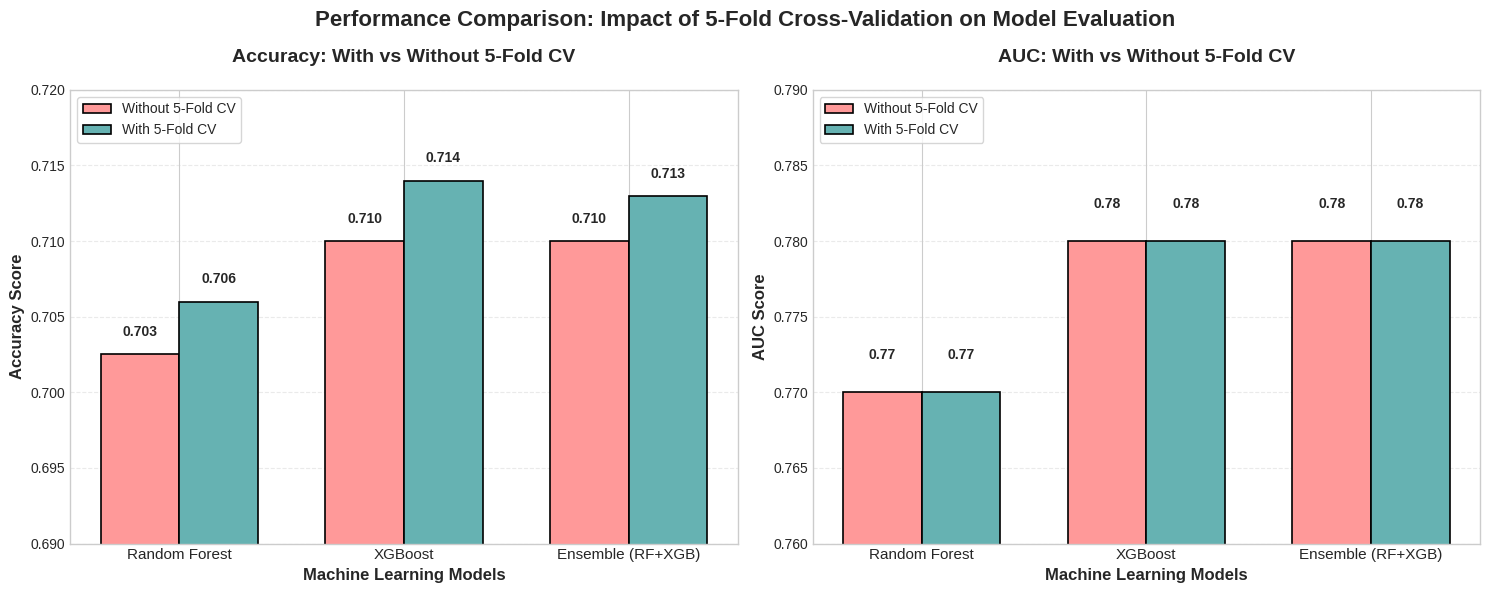

PERFORMANCE DIFFERENCE ANALYSIS (With CV - Without CV)

Random Forest:
  Accuracy: 0.7025 → 0.7060 (Δ = +0.0035)
  AUC:      0.7700 → 0.7700 (Δ = +0.0000)

XGBoost:
  Accuracy: 0.7100 → 0.7140 (Δ = +0.0040)
  AUC:      0.7800 → 0.7800 (Δ = +0.0000)

Ensemble (RF+XGB):
  Accuracy: 0.7100 → 0.7130 (Δ = +0.0030)
  AUC:      0.7800 → 0.7800 (Δ = +0.0000)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set style for better visual appearance
plt.style.use('seaborn-v0_8-whitegrid')

# Model names
models = ['Random Forest', 'XGBoost', 'Ensemble (RF+XGB)']

# Performance data without 5-fold CV
accuracy_without_cv = [0.7025, 0.71, 0.71]
auc_without_cv = [0.77, 0.78, 0.78]

# Performance data with 5-fold CV
accuracy_with_cv = [0.706, 0.714, 0.713]
auc_with_cv = [0.77, 0.78, 0.78]

# Create the figure with subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Set the width of bars and positions
bar_width = 0.35
x_pos = np.arange(len(models))

# Plot 1: Accuracy Comparison
bars1_without = ax1.bar(x_pos - bar_width/2, accuracy_without_cv, bar_width,
                       label='Without 5-Fold CV', color='#FF9999', edgecolor='black', linewidth=1.2)
bars1_with = ax1.bar(x_pos + bar_width/2, accuracy_with_cv, bar_width,
                    label='With 5-Fold CV', color='#66B2B2', edgecolor='black', linewidth=1.2)

ax1.set_title('Accuracy: With vs Without 5-Fold CV', fontsize=14, fontweight='bold', pad=20)
ax1.set_xlabel('Machine Learning Models', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy Score', fontsize=12, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models, fontsize=11)
ax1.set_ylim(0.69, 0.72)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(axis='y', alpha=0.4, linestyle='--')

# Add value labels on accuracy bars
for bars in [bars1_without, bars1_with]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, height + 0.001,
                f'{height:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# Plot 2: AUC Comparison
bars2_without = ax2.bar(x_pos - bar_width/2, auc_without_cv, bar_width,
                       label='Without 5-Fold CV', color='#FF9999', edgecolor='black', linewidth=1.2)
bars2_with = ax2.bar(x_pos + bar_width/2, auc_with_cv, bar_width,
                    label='With 5-Fold CV', color='#66B2B2', edgecolor='black', linewidth=1.2)

ax2.set_title('AUC: With vs Without 5-Fold CV', fontsize=14, fontweight='bold', pad=20)
ax2.set_xlabel('Machine Learning Models', fontsize=12, fontweight='bold')
ax2.set_ylabel('AUC Score', fontsize=12, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(models, fontsize=11)
ax2.set_ylim(0.76, 0.79)
ax2.legend(loc='upper left', frameon=True)
ax2.grid(axis='y', alpha=0.4, linestyle='--')

# Add value labels on AUC bars
for bars in [bars2_without, bars2_with]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, height + 0.002,
                f'{height:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# Add overall title
plt.suptitle('Performance Comparison: Impact of 5-Fold Cross-Validation on Model Evaluation',
             fontsize=16, fontweight='bold', y=0.98)

# Adjust layout
plt.tight_layout()
plt.show()

# Print performance differences
print("="*70)
print("PERFORMANCE DIFFERENCE ANALYSIS (With CV - Without CV)")
print("="*70)

for i, model in enumerate(models):
    acc_diff = accuracy_with_cv[i] - accuracy_without_cv[i]
    auc_diff = auc_with_cv[i] - auc_without_cv[i]

    print(f"\n{model}:")
    print(f"  Accuracy: {accuracy_without_cv[i]:.4f} → {accuracy_with_cv[i]:.4f} (Δ = {acc_diff:+.4f})")
    print(f"  AUC:      {auc_without_cv[i]:.4f} → {auc_with_cv[i]:.4f} (Δ = {auc_diff:+.4f})")